In [4]:
import sys
print(sys.executable)  # путь к Python
print(sys.version)  

/app/.venv/bin/python
3.14.7 (main, Sep 19 2026, 01:01:59) [GCC 14.2.0]


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from scipy.stats import zscore
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV


from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from catboost import CatBoostClassifier


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import roc_auc_score, recall_score

from tqdm.auto import tqdm
import optuna

In [20]:
from sklearn.compose import ColumnTransformer

In [6]:
import tqdm as notebook_tqdm

In [7]:
import subprocess

subprocess.run(["apt-get", "update", "-qq"], check=True)
subprocess.run(["apt-get", "install", "-y", "-qq", "libgomp1"], check=True)

from lightgbm import LGBMClassifier

In [8]:
import lazypredict

In [9]:
pd.set_option('display.max_columns',  10000)
pd.set_option('display.max_info_columns', 10000)

In [10]:
import os

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv()

db_name = os.environ["POSTGRES_DB"]
db_user = os.environ["POSTGRES_USER"]
db_password = os.environ["POSTGRES_PASSWORD"]
db_host = os.environ["POSTGRES_HOST"]
db_port = os.environ["POSTGRES_PORT"]

connection_url = (
    f"postgresql+psycopg2://{db_user}:{db_password}"
    f"@{db_host}:{db_port}/{db_name}"
)

engine = create_engine(connection_url)



Загрузить сведения из PostgreSQL на сервере в notebook 

# EDA исходных датасетов

## Выгрузить Train 

In [11]:
df_train = pd.read_sql("SELECT * FROM train",engine)

df_train.head()

,application_id,client_id,employment_type,hash_id,region_coefficient_extended,age,incoming_amount,internal_decision_code,monthly_income,application_date,education,requested_product,channel,loan_amount,marketing_segment,post_loan_collection_score,region_coefficient,region,interest_rate,months_at_job,dependents,days_until_first_overdue,loan_term_months,siberia_northern_score,target
0,107941,7941,employee,61441390.0,1.0,37.0,30401.28,NaN,30401.28,2025-08-11,bachelor,refinance,partner,63464.49,segment_011,800.87,1.0,east,0.3062,31.0,0.0,61.0,24.0,0.336102,1
1,101163,1163,employee,67321556.0,0.0,60.0,26024.64,manual_review_bad,26024.64,2025-12-29,school,card,mobile,113513.59,segment_067,721.57,1.0,ural,0.1383,90.0,0.0,82.0,6.0,0.560893,1
2,100583,583,contractor,26719968.0,0.0,37.0,21389.83,vip,21389.83,2025-11-09,college,cash,NaN,48993.42,NaN,NaN,1.0,west,0.1729,57.0,1.0,999.0,9.0,NaN,0
3,104082,4082,NaN,45184358.0,0.0,NaN,31617.26,approved_auto,NaN,2025-02-23,college,card,web,77765.78,segment_089,170.91,1.0,ural,0.3585,19.0,0.0,999.0,36.0,NaN,0
4,108413,8413,employee,58267524.0,0.0,60.0,18000.00,approved_auto,18000.00,2025-12-07,bachelor,card,mobile,97254.10,segment_063,NaN,1.0,west,0.1472,405.0,0.0,730.0,9.0,0.741053,0


In [12]:
df_train.shape

(6488, 25)

## Оставить признаки для обучения

In [13]:
df_train_10 = df_train[["age","monthly_income", "employment_type","months_at_job", "education","loan_amount","loan_term_months","dependents", "region", "requested_product", "target"]]
df_train_10 


,age,monthly_income,employment_type,months_at_job,education,loan_amount,loan_term_months,dependents,region,requested_product,target
0,37.0,30401.28,employee,31.0,bachelor,63464.49,24.0,0.0,east,refinance,1
1,60.0,26024.64,employee,90.0,school,113513.59,6.0,0.0,ural,card,1
2,37.0,21389.83,contractor,57.0,college,48993.42,9.0,1.0,west,cash,0
3,NaN,NaN,NaN,19.0,college,77765.78,36.0,0.0,ural,card,0
4,60.0,18000.00,employee,405.0,bachelor,97254.10,9.0,0.0,west,card,0
...,...,...,...,...,...,...,...,...,...,...,...
6483,26.0,21480.58,contractor,41.0,master,162310.63,12.0,1.0,north,pos,1
6484,56.0,28198.35,employee,182.0,college,97850.03,NaN,0.0,south,cash,1
6485,50.0,40575.25,contractor,95.0,bachelor,24912.09,12.0,2.0,west,cash,0
6486,56.0,24783.06,employee,184.0,school,70123.74,12.0,NaN,center,cash,0


## Статистический анализ

In [14]:
df_train_10.describe()

,age,monthly_income,months_at_job,loan_amount,loan_term_months,dependents,target
count,6039.000000,6047.000000,6102.000000,5932.000000,5961.000000,6018.000000,6488.000000
mean,43.636529,42300.330501,102.636676,77673.946999,20.849019,0.805085,0.342170
std,13.600516,21759.337138,86.869559,45118.826338,11.907587,0.900978,0.474473
min,21.000000,18000.000000,0.000000,20000.000000,6.000000,0.000000,0.000000
25%,32.000000,26777.040000,36.000000,47056.442500,12.000000,0.000000,0.000000
50%,44.000000,37717.510000,80.000000,67344.210000,18.000000,1.000000,0.000000
75%,55.000000,52181.895000,149.000000,96352.650000,24.000000,1.000000,1.000000
max,67.000000,282686.980000,506.000000,496150.840000,48.000000,5.000000,1.000000


In [15]:
df_train_10.info()

<class 'pandas.DataFrame'>
RangeIndex: 6488 entries, 0 to 6487
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                6039 non-null   float64
 1   monthly_income     6047 non-null   float64
 2   employment_type    6023 non-null   str    
 3   months_at_job      6102 non-null   float64
 4   education          6040 non-null   str    
 5   loan_amount        5932 non-null   float64
 6   loan_term_months   5961 non-null   float64
 7   dependents         6018 non-null   float64
 8   region             5942 non-null   str    
 9   requested_product  6106 non-null   str    
 10  target             6488 non-null   int64  
dtypes: float64(6), int64(1), str(4)
memory usage: 713.0 KB


In [16]:
df_train_10.drop_duplicates(inplace=True)

In [17]:
df_train_10.select_dtypes(include=["object"]).isna().sum()

/tmp/ipykernel_46464/3601982776.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_train_10.select_dtypes(include=["object"]).isna().sum()


employment_type      465
education            448
region               545
requested_product    382
dtype: int64

In [15]:
# Доля пропусков по каждому столбцу
missing = pd.DataFrame({
    "count": df_train_10.isna().sum(),
    "percent": df_train_10.isna().mean() * 100
})

print(missing.sort_values("percent", ascending=False).round(2))

# Сколько строк имеют хотя бы один пропуск
rows_with_missing = df_train_10.isna().any(axis=1).sum()

print("Строк с пропусками:", rows_with_missing)
print(
    "Доля строк с пропусками, %:",
    round(rows_with_missing / len(df_train_10) * 100, 2)
)

                   count  percent
loan_amount          556     8.58
region               545     8.41
loan_term_months     525     8.10
dependents           468     7.22
employment_type      465     7.18
age                  449     6.93
education            448     6.91
monthly_income       439     6.77
months_at_job        386     5.96
requested_product    382     5.90
target                 0     0.00
Строк с пропусками: 3416
Доля строк с пропусками, %: 52.72


In [16]:
# Количество пропусков в каждой строке
missing_per_row = (df_train_10.isna().mean(axis=1)*100).sort_values(ascending=False).round(2)

# Первые 15 строк с максимальным количеством пропусков
print(
    missing_per_row.head(25)
)

2431    36.36
879     36.36
4409    36.36
4419    36.36
4473    36.36
1596    36.36
886     36.36
5142    36.36
1608    36.36
3605    36.36
1321    36.36
2764    36.36
1130    36.36
5888    36.36
3113    36.36
650     27.27
4522    27.27
4511    27.27
619     27.27
6044    27.27
6008    27.27
134     27.27
3664    27.27
2258    27.27
529     27.27
dtype: float64


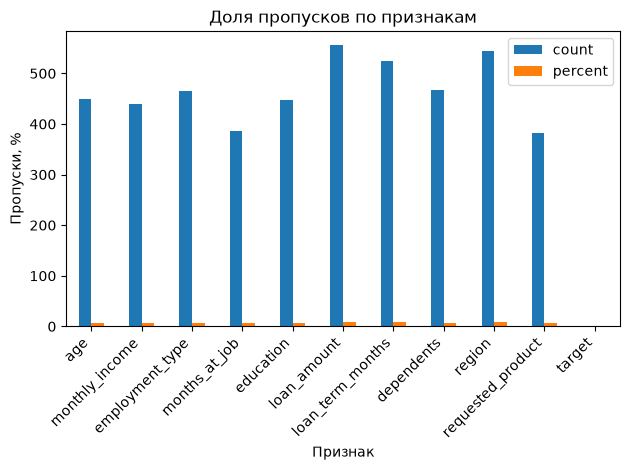

In [17]:
missing = missing[missing > 0]

missing.plot(kind="bar")

plt.title("Доля пропусков по признакам")
plt.xlabel("Признак")
plt.ylabel("Пропуски, %")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

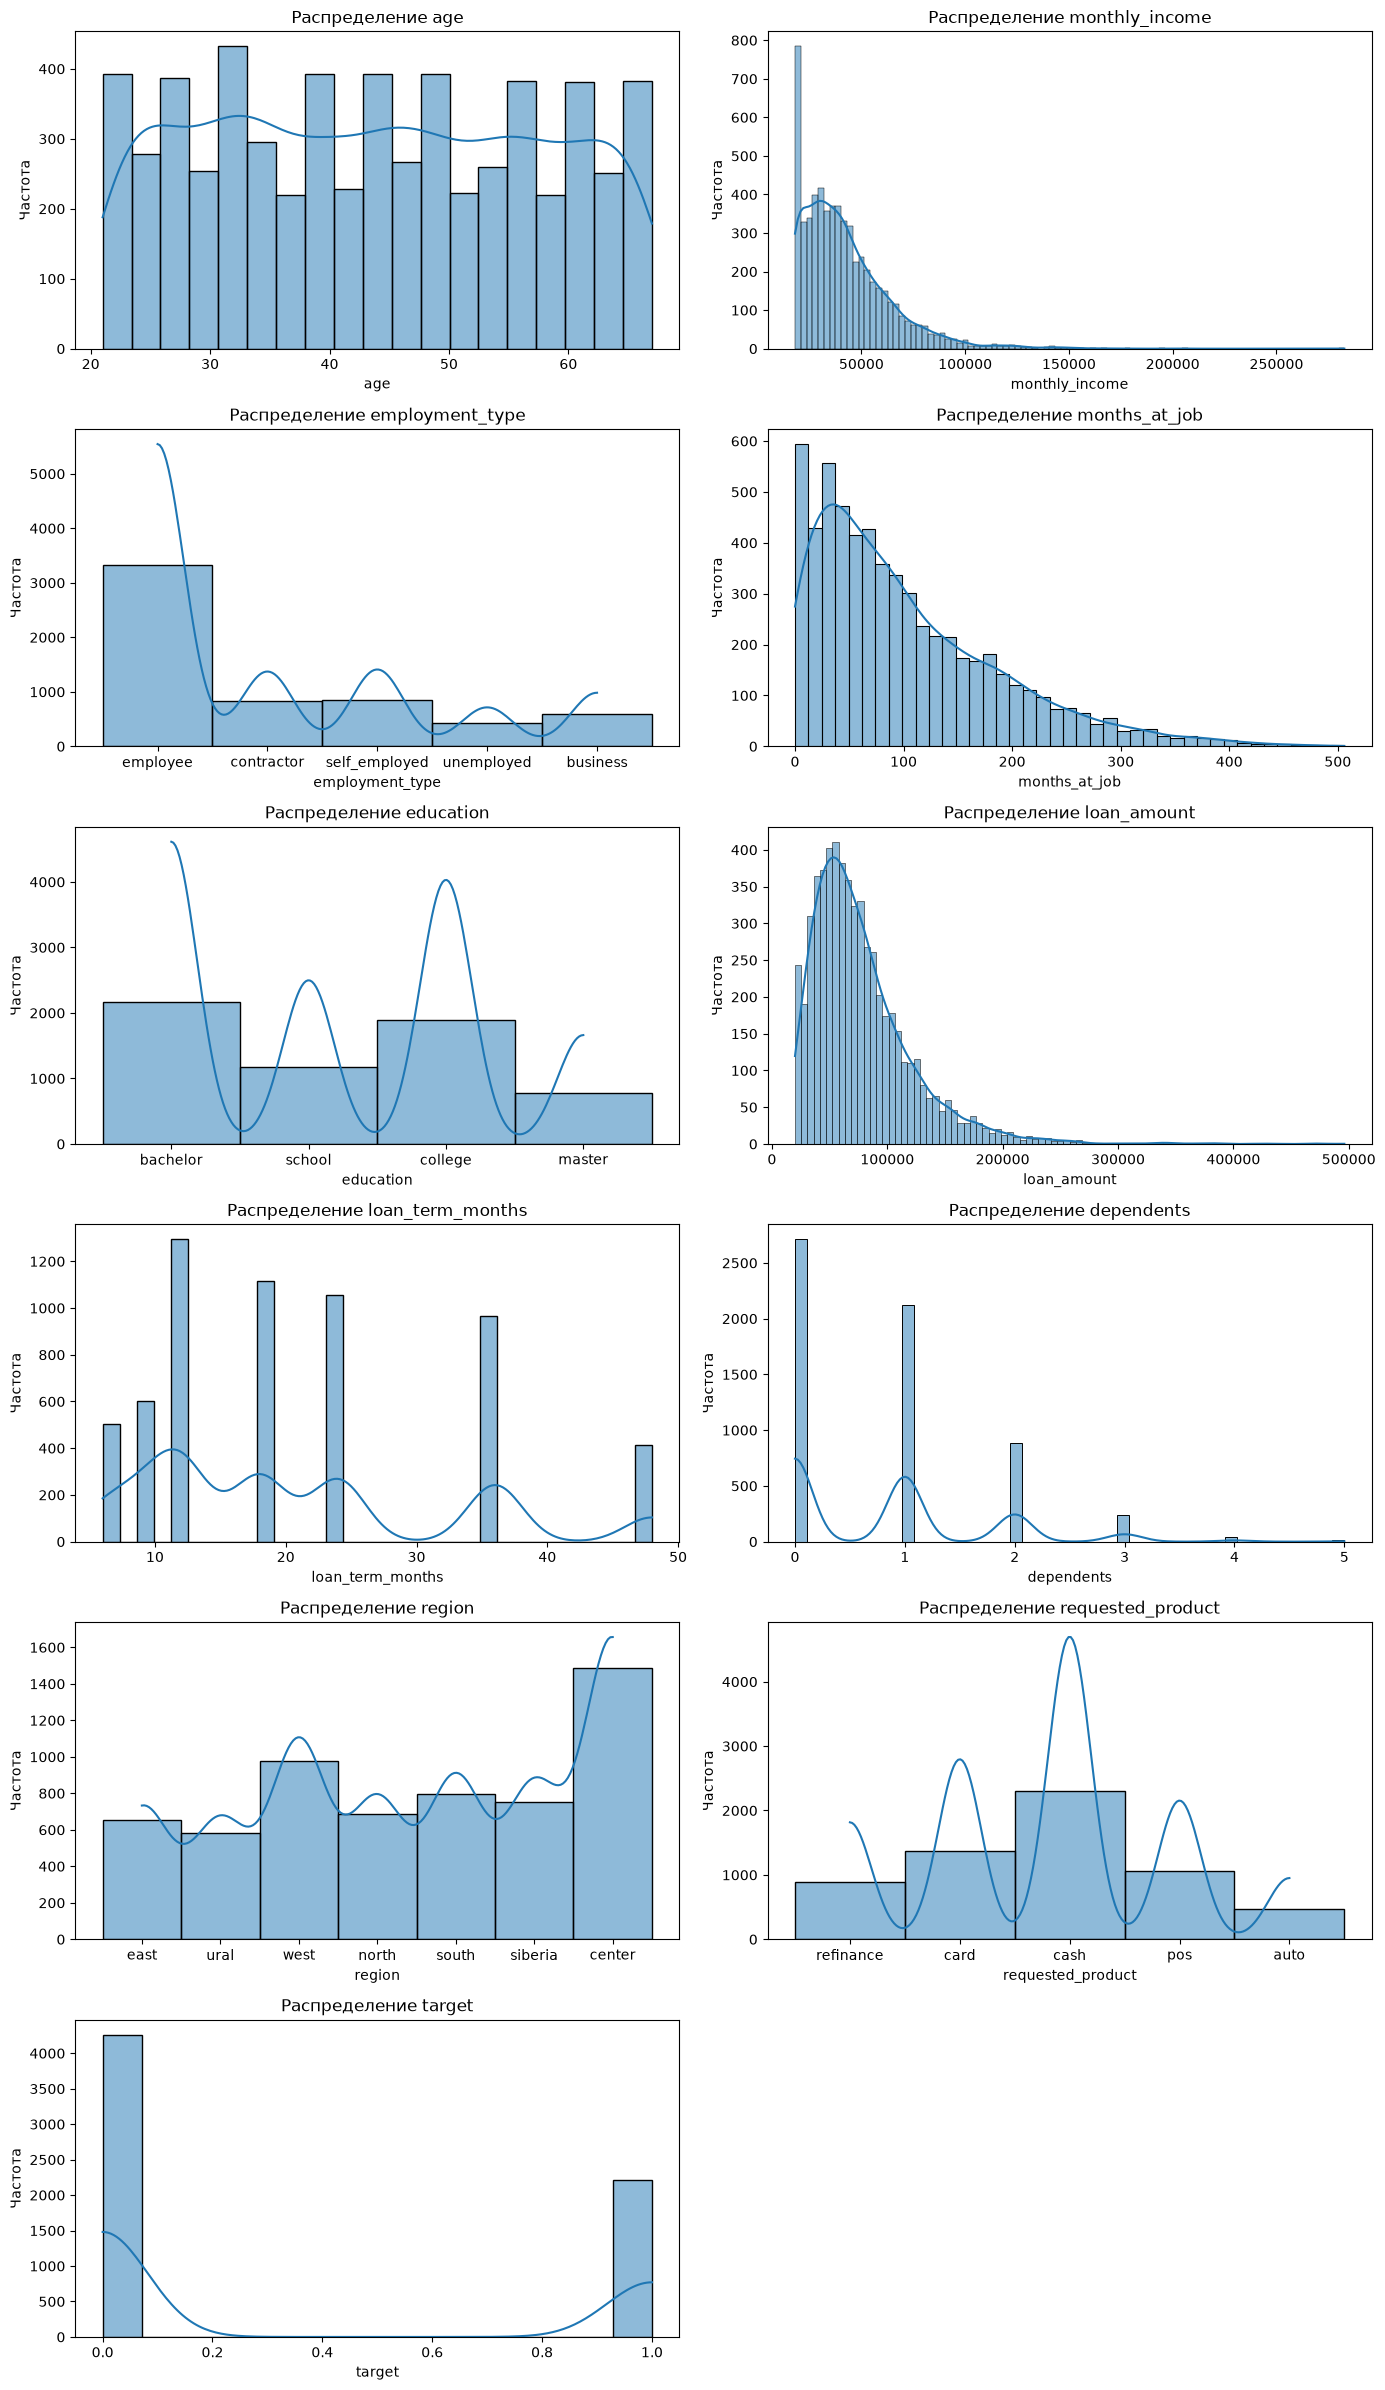

In [18]:
# for col in df_train_10.columns:
#     sns.histplot(kde=True, data=df_train_10, x=col)
#     plt.title(f"Распределение {col}")
#     plt.xlabel(col)
#     plt.ylabel("Частота")
#     plt.show()
    

cols = df_train_10.columns
n_cols = 2
n_rows = math.ceil(len(cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.histplot(data=df_train_10, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f"Распределение {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Частота")

# Удаляем пустые области, если число графиков нечётное
for i in range(len(cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

### Разделение данных на test и train

In [18]:
X_train, X_test, y_train, y_test = train_test_split(df_train_10.drop(columns='target'),df_train_10['target'],
    test_size=0.2,random_state=42,stratify=df_train_10['target'])


In [22]:
# 2. Выбираем признаки
num_cols = [
    "age",
    "monthly_income",
    "months_at_job",
    "loan_amount",
    "loan_term_months",
    "dependents"
]

cat_cols = [
    "education",
    "employment_type",
    "region",
    "requested_product"
]

# 3. Обработка числовых признаков
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 4. Обработка категориальных признаков
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 5. Объединяем предобработку
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols)
])

# 6. Создаём общий Pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        solver="lbfgs"
    ))
])

# 7. Настраиваем кросс-валидацию
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 8. Настраиваем GridSearchCV
param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "classifier__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

# 9. Обучаем и подбираем параметры
grid_search.fit(X_train, y_train)

print("Лучшие параметры:", grid_search.best_params_)
print("Лучший ROC-AUC CV:", grid_search.best_score_)


Лучшие параметры: {'classifier__C': 0.01, 'classifier__class_weight': None}
Лучший ROC-AUC CV: 0.7230979801635666


In [26]:
# 10. Проверяем на отложенной тестовой выборке
best_model = grid_search.best_estimator_

y_proba_test = best_model.predict_proba(X_test)[:, 1]
y_pred_test = best_model.predict(X_test)

print("Test ROC-AUC:", roc_auc_score(y_test, y_proba_test))
print(classification_report(y_test, y_pred_test))

Test ROC-AUC: 0.7233086960199636
              precision    recall  f1-score   support

           0       0.72      0.90      0.80       852
           1       0.63      0.34      0.44       444

    accuracy                           0.71      1296
   macro avg       0.68      0.62      0.62      1296
weighted avg       0.69      0.71      0.68      1296



In [27]:
import joblib
joblib.dump(best_model, "logistic_regression_credit_scoring.pkl")
print("Модель успешно сохранена!")

Модель успешно сохранена!
